# Акцепторы и доноры водородной связи: простой анализ

Мы изучаем две характеристики каждой молекулы из базы DrugBank:

- **A** (`cal_h_bond_acceptor_count`) — сколько в молекуле мест, которые могут **принимать** водородную связь;
- **D** (`cal_h_bond_donor_count`) — сколько мест, которые могут её **отдавать**.

Это обычные целые числа (0, 1, 2, ...). Идём по плану из `data_review.ipynb`.

In [1]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.optimize import minimize

project_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "supporting_functions" / "datacleaner.py").is_file()
)
sys.path.insert(0, str(project_root))

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

RNG = np.random.default_rng(42)

df = pd.read_csv(project_root / "cleaned_data.csv")
a = df["cal_h_bond_acceptor_count"].astype(int).to_numpy()
d = df["cal_h_bond_donor_count"].astype(int).to_numpy()
N = len(df)
print(f"Молекул в данных: {N}, пропусков в A и D нет")

Молекул в данных: 10046, пропусков в A и D нет


## Шаг 1. Почему A и D — случайные величины

Представим, что мы берём из базы **случайную молекулу** и смотрим на её A и D. Заранее мы не знаем, что получится: молекулы очень разные, поэтому числа от выбора к выбору меняются. Именно это и значит «случайная величина». График ниже показывает, как часто встречается каждое значение.

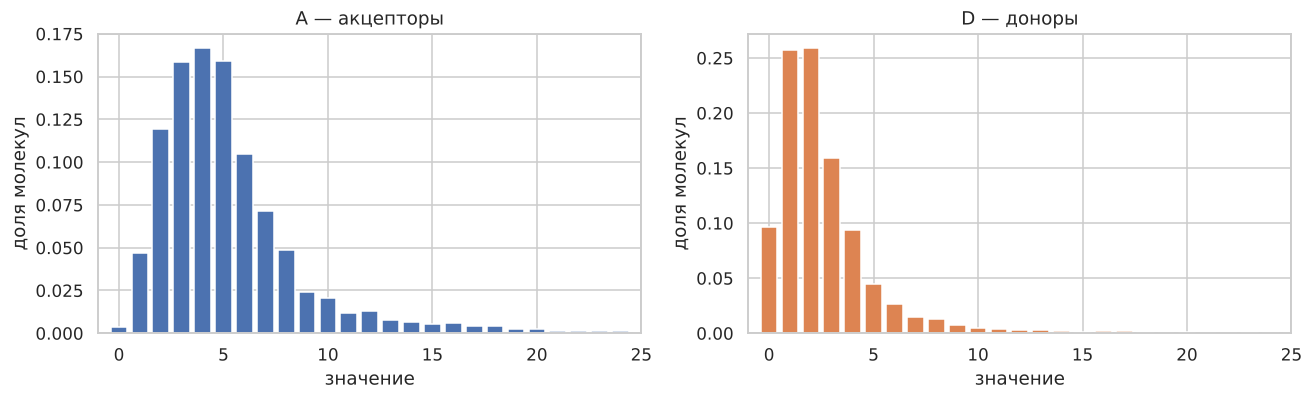

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, x, name, color in zip(axes, (a, d), ("A — акцепторы", "D — доноры"), ("C0", "C1")):
    values, counts = np.unique(x, return_counts=True)
    ax.bar(values, counts / N, color=color)
    ax.set_title(name); ax.set_xlabel("значение"); ax.set_ylabel("доля молекул"); ax.set_xlim(-1, 25)
plt.tight_layout()

**Вывод:** чаще всего у молекулы 3–6 акцепторов и 1–3 донора, но есть и редкие молекулы, у которых этих мест десятки. Поэтому «хвост» справа длинный.


Чтобы убедиться, что A и D ведут себя как настоящие случайные величины, проверим три фундаментальные теоремы теории вероятностей. «Генеральной совокупностью» считаем все 10 046 молекул базы, а случайные выборки берём из неё **с возвращением** (так выборочные значения независимы).

| Теорема | Что делаем | Что должно получиться |
|---|---|---|
| Закон больших чисел | повторяем случайный отбор выборок разного размера | выборочное среднее стабилизируется |
| Центральная предельная теорема | многократно берём выборки одинакового размера и строим распределение их средних | оно приближается к нормальному |
| Гливенко — Кантелли | сравниваем эмпирические функции распределения выборок разного размера | выборочное распределение приближается к распределению полного набора |

Если все три проверки проходят, то A и D можно считать случайными величинами: их выборочные характеристики ведут себя так, как предсказывает теория вероятностей. Это оправдывает вероятностный подход ко всему дальнейшему анализу.

### 1.1. Закон больших чисел

Утверждение: чем больше молекул мы взяли, тем ближе среднее по ним к среднему по всей базе. Берём случайную последовательность из 5 000 молекул и после каждой новой считаем «накопленное среднее». На графике показаны 6 независимых прогонов; если закон работает, все линии должны сойтись к пунктиру. В таблице — насколько в среднем (по 200 прогонам) накопленное среднее отличается от настоящего.

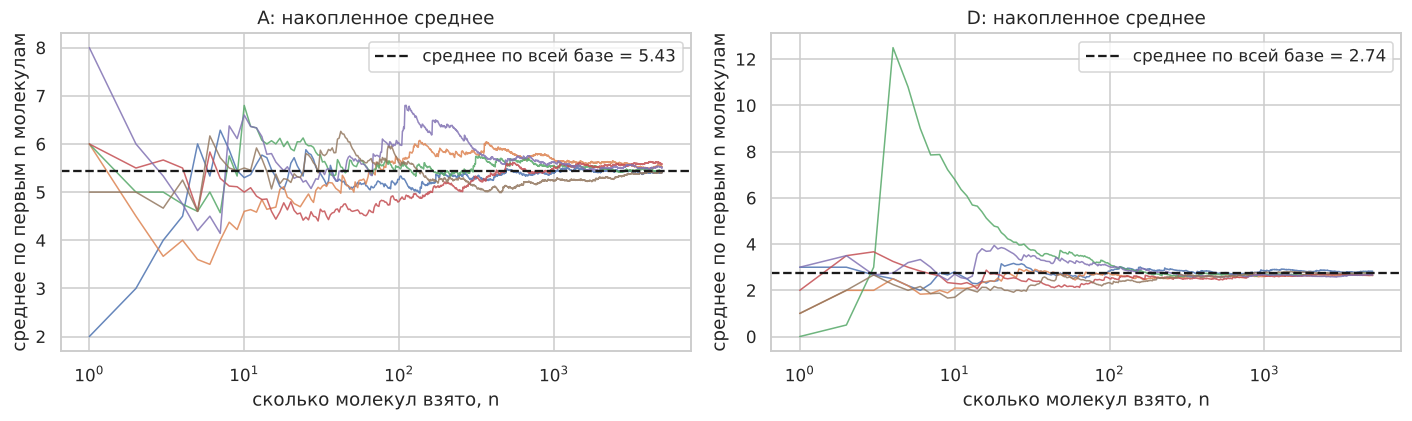

величина,A,D
n,,
10,1.152,0.726
100,0.350,0.254
1000,0.115,0.081
5000,0.045,0.035


In [3]:
rng_s1 = np.random.default_rng(2026)
n_max = 5000
checkpoints = [10, 100, 1000, 5000]
steps = np.arange(1, n_max + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
lln_rows = []
for ax, x, name in zip(axes, (a, d), ("A", "D")):
    runs = np.cumsum(x[rng_s1.integers(0, N, size=(200, n_max))], axis=1) / steps
    for run in runs[:6]:
        ax.plot(steps, run, lw=1, alpha=0.85)
    ax.axhline(x.mean(), color="k", ls="--", label=f"среднее по всей базе = {x.mean():.2f}")
    ax.set_xscale("log"); ax.set_xlabel("сколько молекул взято, n")
    ax.set_ylabel("среднее по первым n молекулам"); ax.set_title(f"{name}: накопленное среднее"); ax.legend()
    for n in checkpoints:
        lln_rows.append({"величина": name, "n": n,
                         "средняя ошибка среднего": np.abs(runs[:, n - 1] - x.mean()).mean()})
plt.tight_layout()
pd.DataFrame(lln_rows).pivot(index="n", columns="величина", values="средняя ошибка среднего").round(3)

### 1.2. Центральная предельная теорема

Утверждение: если много раз брать выборки одного размера $n$ и считать в каждой среднее, то эти средние распределены приблизительно нормально — даже если сама величина нормальной не является. Для сравнения со стандартным нормальным законом приводим средние к виду $z = \dfrac{\bar x - \mu}{\sigma/\sqrt{n}}$ (тогда при выполнении теоремы $z$ должно быть близко к $N(0, 1)$, чёрная кривая).

Для каждого размера делаем по 5 000 выборок. В таблице: **асимметрия** $z$ (у нормального закона 0) и **расстояние Колмогорова–Смирнова** до нормального закона (чем ближе к 0, тем ближе распределение к нормальному).

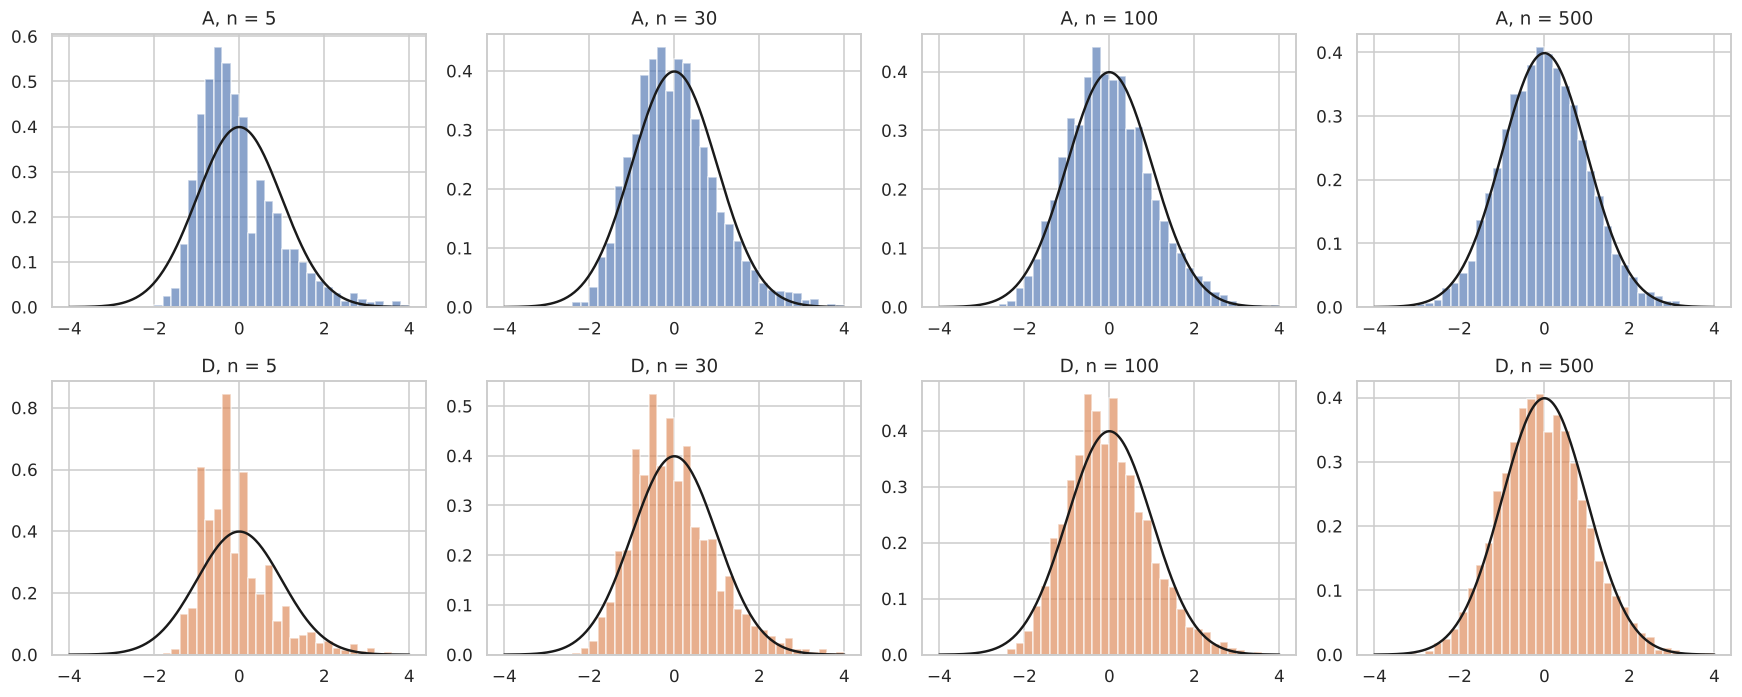

асимметрия z  расстояние до нормального
величина n                                           
A        5           1.680                      0.107
         30          0.749                      0.039
         100         0.412                      0.032
         500         0.158                      0.013
D        5           2.502                      0.141
         30          0.917                      0.065
         100         0.594                      0.048
         500         0.234                      0.032

In [4]:
reps = 5000
sizes_clt = [5, 30, 100, 500]
grid = np.linspace(-4, 4, 200)

fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
clt_rows = []
for row, (x, name) in enumerate(((a, "A"), (d, "D"))):
    mu, sigma = x.mean(), x.std(ddof=0)
    for col, n in enumerate(sizes_clt):
        z = (x[rng_s1.integers(0, N, size=(reps, n))].mean(axis=1) - mu) / (sigma / np.sqrt(n))
        ax = axes[row, col]
        ax.hist(z, bins=40, range=(-4, 4), density=True, alpha=0.65, color=f"C{row}")
        ax.plot(grid, stats.norm.pdf(grid), "k", lw=1.6)
        ax.set_title(f"{name}, n = {n}")
        clt_rows.append({"величина": name, "n": n,
                         "асимметрия z": stats.skew(z),
                         "расстояние до нормального": stats.kstest(z, "norm").statistic})
plt.tight_layout()
pd.DataFrame(clt_rows).set_index(["величина", "n"]).round(3)

### 1.3. Теорема Гливенко — Кантелли

Эмпирическая функция распределения $F_n(x)$ — это доля молекул в выборке, у которых значение не больше $x$. Теорема утверждает, что при росте $n$ она **равномерно** приближается к $F(x)$ всей базы: наибольшее расхождение
$$D_n = \sup_x |F_n(x) - F(x)|$$
стремится к нулю. Слева и посередине — ступенчатые графики $F_n$ для выборок разного размера на фоне $F$ всей базы; справа — как убывает $D_n$ (среднее по 100 выборкам) при росте $n$, пунктиром показана скорость $1/\sqrt{n}$.

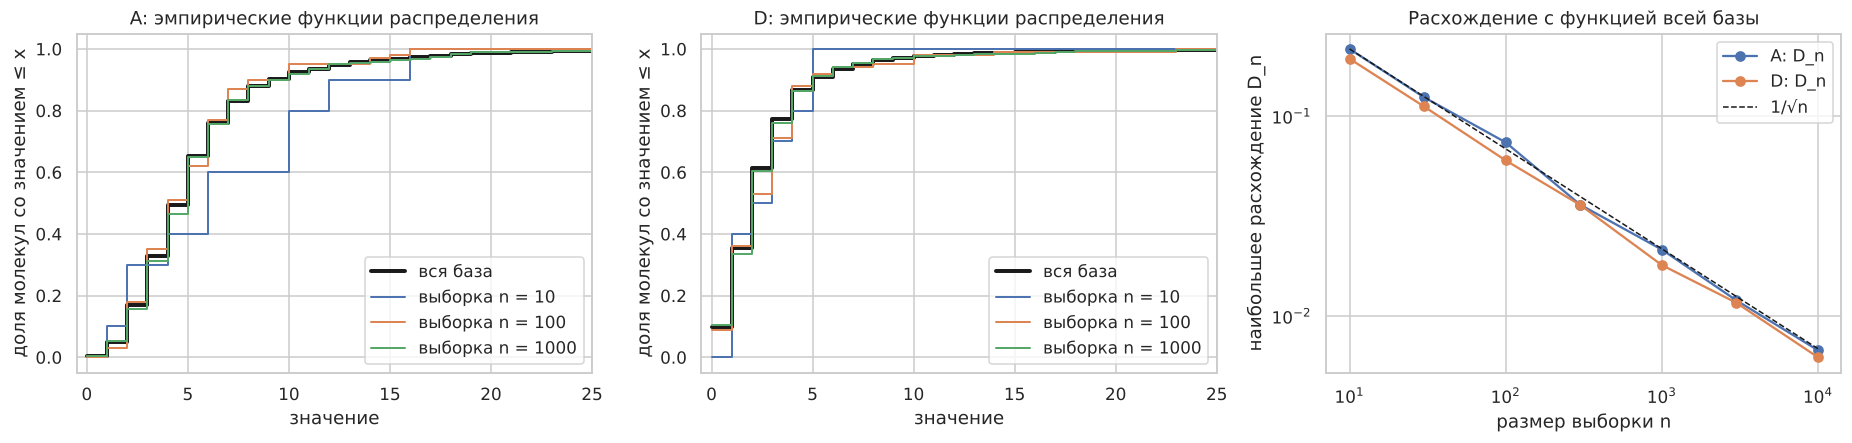

,D_n для A,D_n для D,D_n·√n для A,D_n·√n для D
n,,,,
10,0.216,0.193,0.685,0.612
30,0.124,0.112,0.680,0.611
100,0.074,0.060,0.738,0.599
300,0.036,0.036,0.623,0.621
1000,0.021,0.018,0.678,0.567
3000,0.012,0.012,0.654,0.637
10000,0.007,0.006,0.672,0.620


In [5]:
support = np.arange(0, max(a.max(), d.max()) + 1)

def ecdf(x):
    return np.cumsum(np.bincount(x, minlength=len(support))) / len(x)

sizes_gc = [10, 30, 100, 300, 1000, 3000, 10000]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
dn = {}
for ax, x, name in zip(axes[:2], (a, d), ("A", "D")):
    full = ecdf(x)
    ax.step(support, full, where="post", color="k", lw=2.6, label="вся база")
    for n in (10, 100, 1000):
        ax.step(support, ecdf(x[rng_s1.integers(0, N, size=n)]), where="post", lw=1.3, label=f"выборка n = {n}")
    ax.set_xlim(-0.5, 25); ax.set_xlabel("значение"); ax.set_ylabel("доля молекул со значением ≤ x")
    ax.set_title(f"{name}: эмпирические функции распределения"); ax.legend(loc="lower right")
    dn[name] = [np.mean([np.abs(ecdf(x[rng_s1.integers(0, N, size=n)]) - full).max() for _ in range(100)])
                for n in sizes_gc]

ax = axes[2]
for name, color in (("A", "C0"), ("D", "C1")):
    ax.loglog(sizes_gc, dn[name], "o-", color=color, label=f"{name}: D_n")
ax.loglog(sizes_gc, dn["A"][0] * np.sqrt(sizes_gc[0] / np.array(sizes_gc)), "k--", lw=1, label="1/√n")
ax.set_xlabel("размер выборки n"); ax.set_ylabel("наибольшее расхождение D_n")
ax.set_title("Расхождение с функцией всей базы"); ax.legend()
plt.tight_layout()

pd.DataFrame({"D_n для A": dn["A"], "D_n для D": dn["D"],
              "D_n·√n для A": np.array(dn["A"]) * np.sqrt(sizes_gc),
              "D_n·√n для D": np.array(dn["D"]) * np.sqrt(sizes_gc)},
             index=pd.Index(sizes_gc, name="n")).round(3)

**Вывод по проверке:**

Все три теоремы выполняются, значит A и D ведут себя как настоящие случайные величины.


## Шаг 2. Связаны ли A и D между собой

Проверим это двумя числами — коэффициентами корреляции (от −1 до 1, чем ближе к ±1, тем сильнее связь):

- **Пирсон** ищет прямолинейную связь и сильно реагирует на редкие огромные значения;
- **Спирмен** смотрит только на порядок значений, поэтому к огромным значениям устойчив.

Гипотеза проверки: $H_0$ — «A и D не связаны». Если p-value меньше 0,05, считаем, что связь не случайна.

Пирсон (все данные):             0.85
Пирсон (без самых больших 1%):   0.77
Спирмен:                         0.65   (p-value меньше 1e-300, то есть практически 0)


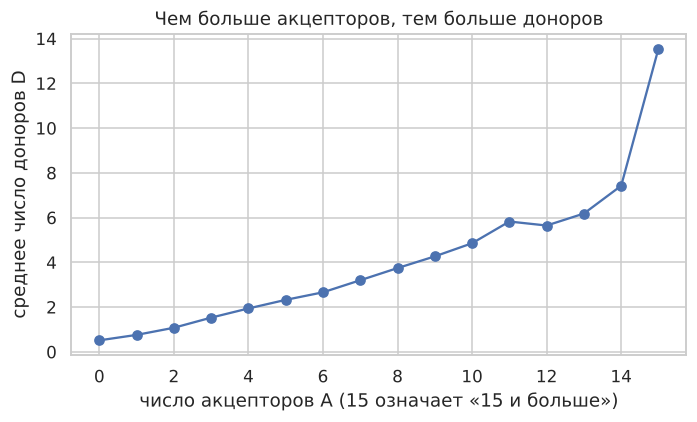

In [6]:
pearson = stats.pearsonr(a, d).statistic
spearman = stats.spearmanr(a, d)
core = (a <= np.percentile(a, 99)) & (d <= np.percentile(d, 99))   # без самых больших 1% молекул
pearson_core = stats.pearsonr(a[core], d[core]).statistic

print(f"Пирсон (все данные):             {pearson:.2f}")
print(f"Пирсон (без самых больших 1%):   {pearson_core:.2f}")
p_text = "меньше 1e-300, то есть практически 0" if spearman.pvalue < 1e-300 else f"{spearman.pvalue:.1e}"
print(f"Спирмен:                         {spearman.statistic:.2f}   (p-value {p_text})")

# наглядно: сколько доноров в среднем у молекул с данным числом акцепторов
a_cut = np.minimum(a, 15)
mean_d = pd.Series(d).groupby(a_cut).mean()
plt.figure(figsize=(6.5, 4))
plt.plot(mean_d.index, mean_d.values, "o-")
plt.xlabel("число акцепторов A (15 означает «15 и больше»)")
plt.ylabel("среднее число доноров D")
plt.title("Чем больше акцепторов, тем больше доноров")
plt.tight_layout()

**Вывод:** A и D действительно связаны — чем больше у молекулы акцепторов, тем в среднем больше доноров (p-value практически ноль, значит, это не случайность). Но число 0,85 из корреляционной матрицы немного завышено: его подтягивают редкие очень большие молекулы. Без них оно 0,77, а по Спирмену 0,65. Связь сильная, но не «один в один».

## Шаг 3. Хватает ли данных: сходятся ли оценки к «правде»

Возьмём «правду» — среднее и корреляцию по **всей** базе. Теперь будем брать случайные выборки разного размера (по 300 выборок каждого размера) и смотреть, насколько оценки по ним отличаются от «правды». Если оценка хорошая, то чем больше выборка, тем кучнее она ложится вокруг правильного значения. Это и называется **состоятельностью**.

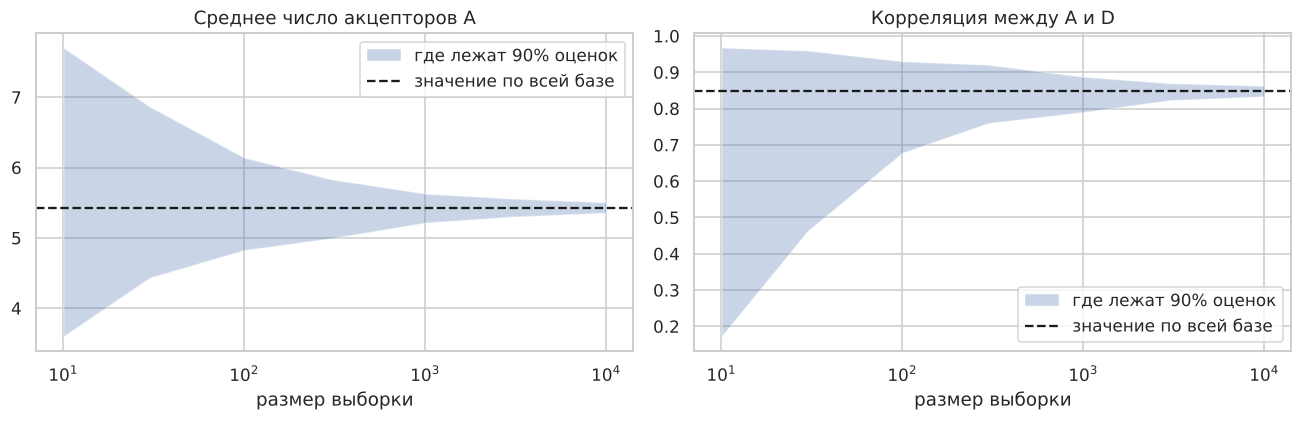

,разброс оценок среднего A,разброс оценок корреляции
размер выборки,,
10,1.279,0.242
30,0.759,0.153
100,0.414,0.078
300,0.259,0.051
1000,0.128,0.029
3000,0.075,0.014
10000,0.044,0.009


In [7]:
sizes = [10, 30, 100, 300, 1000, 3000, 10000]
repeats = 300
true_mean, true_corr = a.mean(), np.corrcoef(a, d)[0, 1]

means, corrs = {}, {}
for n in sizes:
    idx = RNG.integers(0, N, size=(repeats, n))
    A_s, D_s = a[idx], d[idx]
    means[n] = A_s.mean(axis=1)
    Ac, Dc = A_s - A_s.mean(1, keepdims=True), D_s - D_s.mean(1, keepdims=True)
    corrs[n] = (Ac * Dc).sum(1) / np.sqrt((Ac ** 2).sum(1) * (Dc ** 2).sum(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, est, truth, title in ((axes[0], means, true_mean, "Среднее число акцепторов A"),
                              (axes[1], corrs, true_corr, "Корреляция между A и D")):
    lo = [np.percentile(est[n], 5) for n in sizes]
    hi = [np.percentile(est[n], 95) for n in sizes]
    ax.fill_between(sizes, lo, hi, alpha=0.3, label="где лежат 90% оценок")
    ax.axhline(truth, color="k", ls="--", label="значение по всей базе")
    ax.set_xscale("log"); ax.set_xlabel("размер выборки"); ax.set_title(title); ax.legend()
plt.tight_layout()

spread = pd.DataFrame({
    "разброс оценок среднего A": [means[n].std() for n in sizes],
    "разброс оценок корреляции": [corrs[n].std() for n in sizes],
}, index=pd.Index(sizes, name="размер выборки")).round(3)
spread

**Вывод:** чем больше выборка, тем уже «коридор» оценок и тем ближе он к настоящему значению. На 1000 молекул среднее уже определено довольно точно, на нескольких тысячах — очень точно. Значит, и среднее, и корреляция — надёжные оценки, а наших 10 тысяч молекул для них более чем достаточно.

## Шаг 4. Как выглядят данные и что с ними делать

Посмотрим на основные числа и на «выбросы» — необычно большие значения. Затем проверим, помогает ли логарифм сделать распределение более симметричным (асимметрия около 0 — значит, симметрично).

In [8]:
def summary(x):
    q1, q3 = np.percentile(x, [25, 75])
    border = q3 + 1.5 * (q3 - q1)
    return pd.Series({
        "минимум": x.min(), "медиана": np.median(x), "среднее": round(x.mean(), 2), "максимум": x.max(),
        "стандартное отклонение": round(x.std(ddof=1), 2),
        "асимметрия": round(stats.skew(x), 2),
        "асимметрия после ln(1+x)": round(stats.skew(np.log1p(x)), 2),
        "молекул-«выбросов»": int((x > border).sum()),
    })

pd.DataFrame({"A": summary(a), "D": summary(d)})

,A,D
минимум,0.00,0.00
медиана,5.00,2.00
среднее,5.43,2.74
максимум,79.00,60.00
стандартное отклонение,4.31,3.15
асимметрия,4.16,5.41
асимметрия после ln(1+x),0.34,0.34
молекул-«выбросов»,767.00,638.00


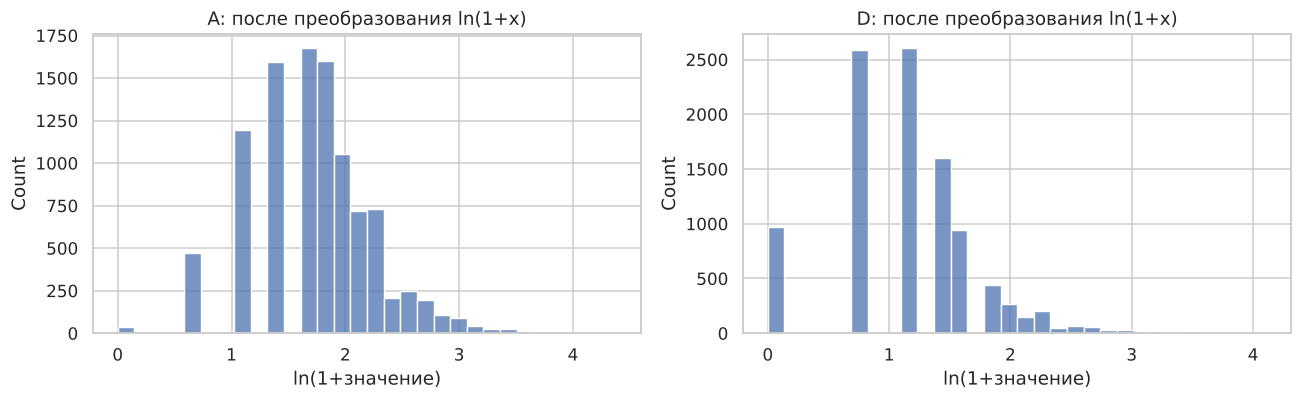

,name,cal_h_bond_acceptor_count,cal_h_bond_donor_count,cal_molecular_weight
4441,Delcasertib,79.0,55.0,2880.310
4314,Ularitide,63.0,60.0,3505.926
4809,DiaPep 277,60.0,33.0,2390.768
9696,Zilucoplan,59.0,28.0,3562.229
9312,Avexitide,53.0,45.0,3369.800


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, x, name in zip(axes, (a, d), ("A", "D")):
    sns.histplot(np.log1p(x), bins=30, ax=ax)
    ax.set_title(f"{name}: после преобразования ln(1+x)"); ax.set_xlabel("ln(1+значение)")
plt.tight_layout()
df.nlargest(5, "cal_h_bond_acceptor_count")[["name", "cal_h_bond_acceptor_count", "cal_h_bond_donor_count", "cal_molecular_weight"]]

**Вывод:** большинство значений маленькие, но есть редкие гигантские (до 79 акцепторов и 60 доноров). Это не ошибки: таблица показывает, что это очень тяжёлые молекулы (масса 2400–3600), поэтому удалять их не нужно. Логарифм делает распределение гораздо симметричнее (асимметрия падает с 4,16 до 0,34 у A и с 5,41 до 0,34 у D), поэтому для методов, которые любят «ровные» данные, лучше брать `ln(1+x)`.

## Шаг 5. Выборка «с возвращением» и «без возвращения»

- **С возвращением:** вытащили молекулу, записали, вернули обратно — она может попасться снова.
- **Без возвращения:** вытащили — и больше не кладём.

Сравним, насколько точно по таким выборкам определяется среднее A (по 500 повторов).

In [10]:
rows = []
for n in [100, 1000, 5000, 9000]:
    with_return = a[RNG.integers(0, N, size=(500, n))].mean(axis=1)
    without_return = np.array([a[RNG.choice(N, size=n, replace=False)].mean() for _ in range(500)])
    rows.append({"размер выборки": n,
                 "оценка среднего (с возвр.)": with_return.mean(),
                 "оценка среднего (без возвр.)": without_return.mean(),
                 "разброс оценок (с возвр.)": with_return.std(),
                 "разброс оценок (без возвр.)": without_return.std()})
print(f"Настоящее среднее A по всей базе: {a.mean():.3f}")
pd.DataFrame(rows).set_index("размер выборки").round(3)

Настоящее среднее A по всей базе: 5.428


,оценка среднего (с возвр.),оценка среднего (без возвр.),разброс оценок (с возвр.),разброс оценок (без возвр.)
размер выборки,,,,
100,5.422,5.411,0.440,0.419
1000,5.426,5.428,0.136,0.128
5000,5.428,5.428,0.060,0.041
9000,5.431,5.429,0.047,0.015


**Вывод:** оба способа дают правильное среднее. Разница только в точности: когда выборка мала по сравнению с базой, способы почти не отличаются, а когда мы берём почти всю базу, выборка «без возвращения» оказывается намного точнее (мы ведь почти пересчитали все молекулы), и разброс у неё почти исчезает.

## Шаг 6. Какое распределение подходит

Для «счётных» величин сначала пробуют **распределение Пуассона**. У него есть особенность: дисперсия (разброс) равна среднему. Проверим, так ли это у нас. Если разброс заметно больше, берут более гибкое **отрицательное биномиальное** распределение. Модели сравниваем по AIC — чем он **меньше**, тем лучше модель.

In [11]:
def fit_models(x):
    values, counts = np.unique(x, return_counts=True)
    lam = x.mean()
    ll_pois = (counts * stats.poisson.logpmf(values, lam)).sum()

    m, v = x.mean(), x.var(ddof=1)
    p0 = m / v; r0 = m * p0 / (1 - p0)
    sig = lambda t: 1 / (1 + np.exp(-t))
    nll = lambda t: -(counts * stats.nbinom.logpmf(values, np.exp(t[0]), sig(t[1]))).sum()
    res = minimize(nll, [np.log(r0), np.log(p0 / (1 - p0))], method="Nelder-Mead")
    r, p = np.exp(res.x[0]), sig(res.x[1])
    return lam, (r, p), 2 * 1 - 2 * ll_pois, 2 * 2 + 2 * res.fun

rows, fitted = [], {}
for name, x in (("A", a), ("D", d)):
    lam, (r, p), aic_p, aic_nb = fit_models(x)
    fitted[name] = (lam, r, p)
    rows.append({"величина": name, "среднее": x.mean(), "дисперсия": x.var(ddof=1),
                 "дисперсия / среднее": x.var(ddof=1) / x.mean(),
                 "AIC Пуассон": aic_p, "AIC отриц. биномиальное": aic_nb})
pd.DataFrame(rows).set_index("величина").round(2)

,среднее,дисперсия,дисперсия / среднее,AIC Пуассон,AIC отриц. биномиальное
величина,,,,,
A,5.43,18.59,3.42,58116.46,51387.39
D,2.74,9.90,3.62,48273.46,42289.71


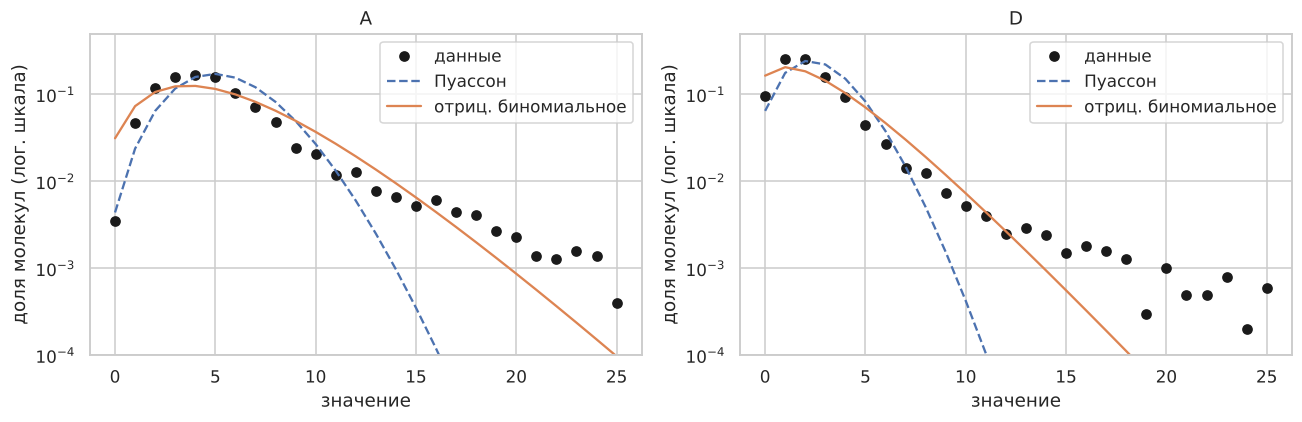

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ks = np.arange(0, 26)
for ax, (name, x) in zip(axes, (("A", a), ("D", d))):
    lam, r, p = fitted[name]
    ax.semilogy(ks, np.bincount(x, minlength=26)[:26] / N, "ko", label="данные")
    ax.semilogy(ks, stats.poisson.pmf(ks, lam), "--", label="Пуассон")
    ax.semilogy(ks, stats.nbinom.pmf(ks, r, p), "-", label="отриц. биномиальное")
    ax.set_ylim(1e-4, 0.5); ax.set_xlabel("значение"); ax.set_ylabel("доля молекул (лог. шкала)")
    ax.set_title(name); ax.legend()
plt.tight_layout()

**Вывод:** у обеих величин разброс в 3–4 раза больше среднего, поэтому Пуассон не подходит (на графике его линия резко обрывается там, где у данных ещё есть «хвост»). Отрицательное биномиальное распределение справляется заметно лучше (AIC меньше почти на 6 000–6 700), но тоже не идеально: хвост у настоящих данных всё равно тяжелее. Для практических целей его можно использовать как приближение; точнее модель можно сделать, если смешать два распределения (это сделано в расширенной версии анализа).

## Шаг 7. Проверка гипотез

Уровень значимости везде 0,05: если p-value меньше 0,05, считаем, что различие или связь не случайны.

### Гипотеза 1. Зависят ли A и D от физического состояния вещества (`state`)

Кодируем `state` числами: **0** — значение пропущено («пустые строки»), **1** — `liquid`, **2** — `solid`. Единственная молекула с состоянием `gas` слишком одна для сравнения и в этот анализ не входит.

- $H_0$: распределения A (и D) во всех трёх группах одинаковы, то есть от `state` они не зависят.
- $H_1$: хотя бы в одной группе распределение отличается.

Проверяем критерием Краскела–Уоллиса: он сравнивает сразу три группы. Если он значим, попарно сравниваем группы критерием Манна–Уитни с поправкой Холма на число сравнений. Уровень значимости 0,05.

In [13]:
state_code = np.full(N, -1)
state_code[df["state"].isna().to_numpy()] = 0
state_code[(df["state"] == "liquid").to_numpy()] = 1
state_code[(df["state"] == "solid").to_numpy()] = 2
keep = state_code >= 0

LABELS = {0: "0 — state пропущен", 1: "1 — liquid", 2: "2 — solid"}
COLORS = {0: "#E69F00", 1: "#0072B2", 2: "#009E73"}     # оранжевый, синий, зелёный

pd.Series({LABELS[g]: int((state_code == g).sum()) for g in (0, 1, 2)}, name="молекул").to_frame()

,молекул
0 — state пропущен,2346
1 — liquid,114
2 — solid,7585


На графике показаны молекулы с A ≤ 30 и D ≤ 20; за его пределами осталось 58 молекул.


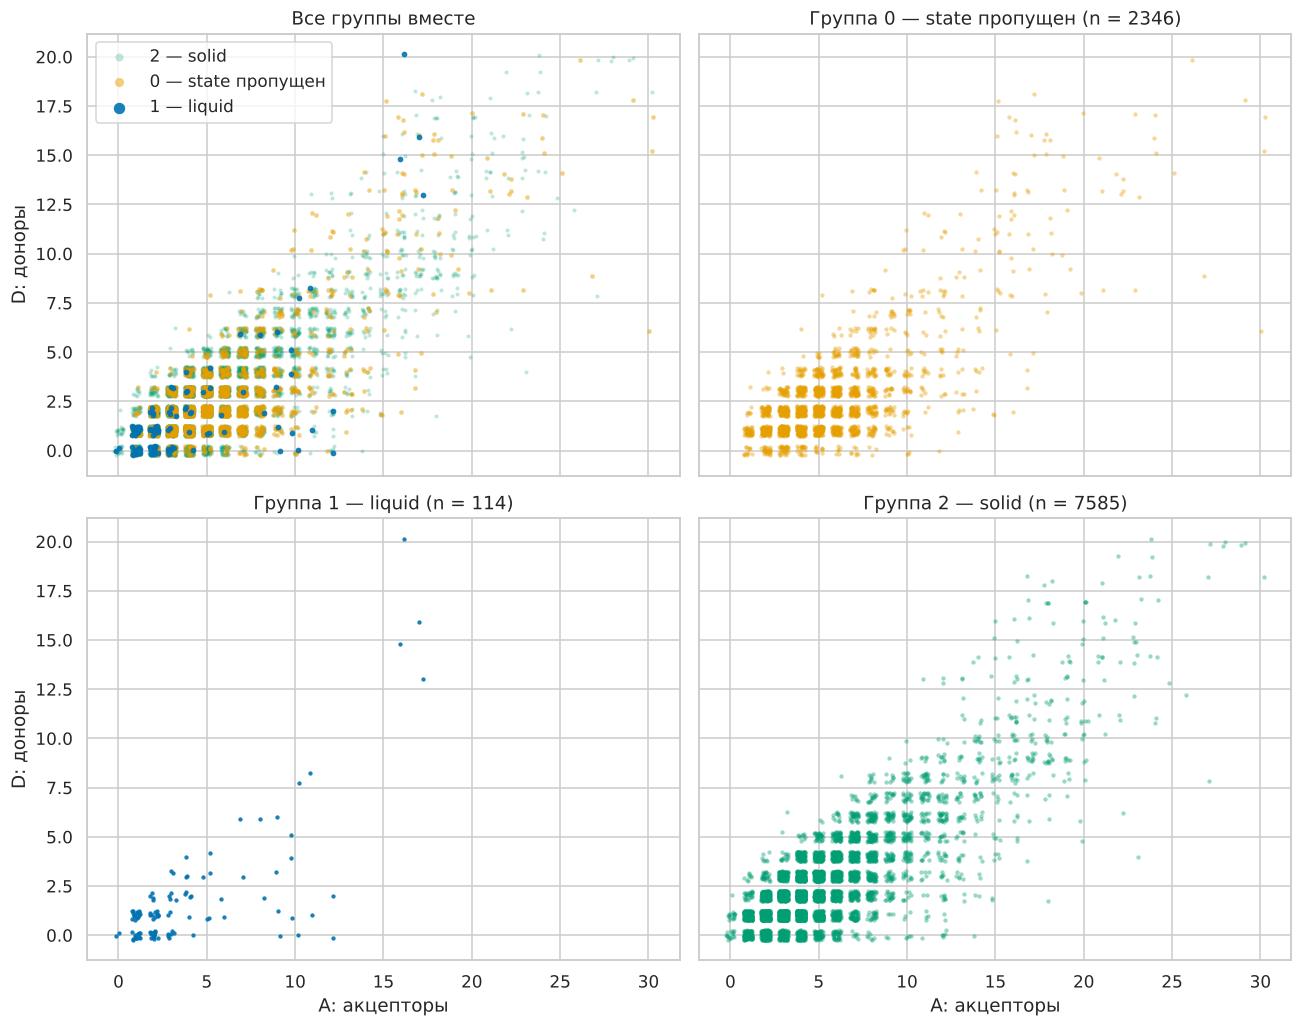

In [14]:
jitter = RNG.uniform(-0.25, 0.25, size=(2, N))
in_view = (a <= 30) & (d <= 20)

fig, axes = plt.subplots(2, 2, figsize=(12, 9.5), sharex=True, sharey=True)
ax = axes[0, 0]
for g, size, alpha in ((2, 7, 0.25), (0, 9, 0.5), (1, 14, 0.9)):
    m = (state_code == g) & in_view
    ax.scatter(a[m] + jitter[0, m], d[m] + jitter[1, m], s=size, alpha=alpha, color=COLORS[g], label=LABELS[g], linewidths=0)
ax.set_title("Все группы вместе"); ax.legend(markerscale=2)
for ax, g in zip((axes[0, 1], axes[1, 0], axes[1, 1]), (0, 1, 2)):
    m = (state_code == g) & in_view
    ax.scatter(a[m] + jitter[0, m], d[m] + jitter[1, m], s=8, alpha=0.4 if g != 1 else 0.9, color=COLORS[g], linewidths=0)
    ax.set_title(f"Группа {LABELS[g]} (n = {int((state_code == g).sum())})")
for ax in axes[1]:
    ax.set_xlabel("A: акцепторы")
for ax in axes[:, 0]:
    ax.set_ylabel("D: доноры")
plt.tight_layout()
print(f"На графике показаны молекулы с A ≤ 30 и D ≤ 20; за его пределами осталось {int((~in_view & keep).sum())} молекул.")

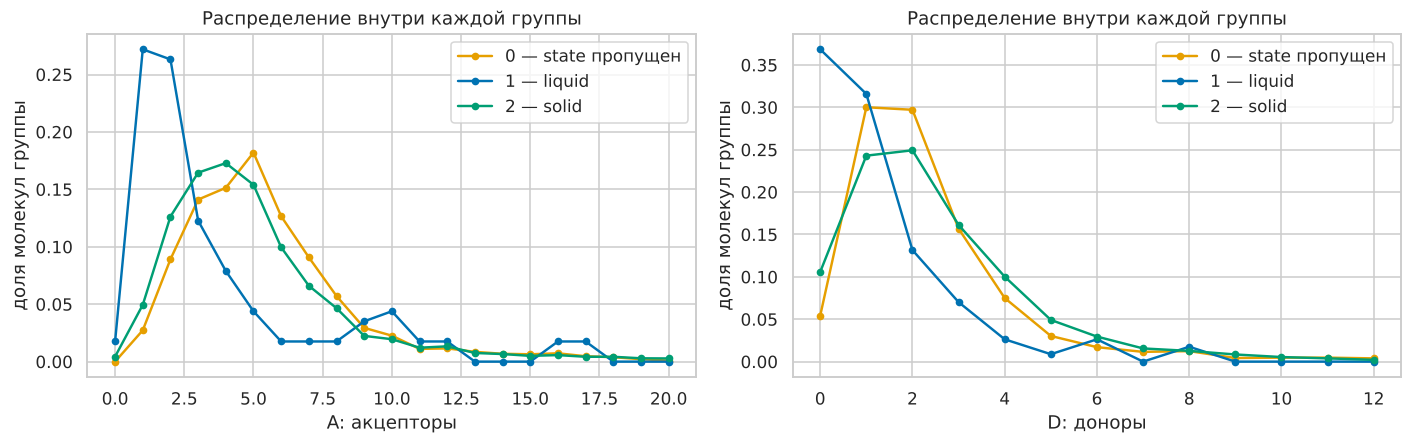

,n,медиана A,среднее A,медиана D,среднее D,корреляция A и D (Спирмен)
группа,,,,,,
0 — state пропущен,2346,5.0,5.94,2.0,2.84,0.56
1 — liquid,114,2.0,3.81,1.0,1.80,0.57
2 — solid,7585,4.0,5.29,2.0,2.72,0.67


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, x, name, xmax in zip(axes, (a, d), ("A: акцепторы", "D: доноры"), (20, 12)):
    for g in (0, 1, 2):
        values = x[state_code == g]
        share = np.bincount(values, minlength=xmax + 1)[:xmax + 1] / len(values)
        ax.plot(np.arange(xmax + 1), share, "o-", color=COLORS[g], label=LABELS[g], lw=1.6, ms=4)
    ax.set_xlabel(name); ax.set_ylabel("доля молекул группы"); ax.set_title("Распределение внутри каждой группы"); ax.legend()
plt.tight_layout()

group_table = pd.DataFrame([{
    "группа": LABELS[g], "n": int((state_code == g).sum()),
    "медиана A": np.median(a[state_code == g]), "среднее A": a[state_code == g].mean(),
    "медиана D": np.median(d[state_code == g]), "среднее D": d[state_code == g].mean(),
    "корреляция A и D (Спирмен)": stats.spearmanr(a[state_code == g], d[state_code == g]).statistic,
} for g in (0, 1, 2)]).set_index("группа").round(2)
group_table

In [16]:
def p_str(p):
    return "< 1e-300" if p == 0 else (f"{p:.2e}" if p < 1e-4 else f"{p:.4f}")

# 1) критерий Краскела–Уоллиса для трёх групп
kw_rows = []
for name, x in (("A", a), ("D", d)):
    H, p = stats.kruskal(*[x[state_code == g] for g in (0, 1, 2)])
    n_all = int(keep.sum())
    kw_rows.append({"величина": name, "H": H, "p-value": p_str(p),
                    "размер эффекта ε²": H / (n_all - 1),
                    "H0 отвергается": "да" if p < 0.05 else "нет"})
print("Краскел–Уоллис (есть ли различие хотя бы между двумя группами):")
display_kw = pd.DataFrame(kw_rows).set_index("величина").round(4)
print(display_kw.to_string())

# 2) попарные сравнения с поправкой Холма
pairs = [(0, 1), (0, 2), (1, 2)]
pair_rows = []
for name, x in (("A", a), ("D", d)):
    for g1, g2 in pairs:
        u1, u2 = x[state_code == g1], x[state_code == g2]
        res = stats.mannwhitneyu(u1, u2)
        pair_rows.append({"величина": name, "сравнение": f"{g1} и {g2}", "p-value": res.pvalue,
                          "r (эффект)": 2 * res.statistic / (len(u1) * len(u2)) - 1})
pair_table = pd.DataFrame(pair_rows)
order = pair_table["p-value"].argsort().to_numpy()
holm, running = np.empty(len(pair_table)), 0.0
for rank, i in enumerate(order):
    running = max(running, (len(pair_table) - rank) * pair_table["p-value"].iloc[i])
    holm[i] = min(1.0, running)
pair_table["p с поправкой Холма"] = holm
pair_table["различие значимо"] = np.where(holm < 0.05, "да", "нет")
pair_table["p-value"] = pair_table["p-value"].map(p_str)
pair_table["p с поправкой Холма"] = pair_table["p с поправкой Холма"].map(p_str)
print()
print("Попарно (r > 0 — значения в первой группе в среднем больше; |r| около 0,1 — слабый эффект, 0,3 — средний, 0,5 — сильный):")
pair_table.set_index(["величина", "сравнение"]).round(3)

Краскел–Уоллис (есть ли различие хотя бы между двумя группами):
                 H   p-value  размер эффекта ε² H0 отвергается
величина                                                      
A         137.4247  1.44e-30             0.0137             да
D          56.6203  5.07e-13             0.0056             да

Попарно (r > 0 — значения в первой группе в среднем больше; |r| около 0,1 — слабый эффект, 0,3 — средний, 0,5 — сильный):


p-value  r (эффект) p с поправкой Холма различие значимо
величина сравнение                                                           
A        0 и 1      6.76e-17       0.459            3.38e-16               да
         0 и 2      4.63e-20       0.124            2.78e-19               да
         1 и 2      3.07e-12      -0.377            6.14e-12               да
D        0 и 1      4.96e-14       0.405            1.98e-13               да
         0 и 2        0.1052      -0.022              0.1052              нет
         1 и 2      4.20e-13      -0.388            1.26e-12               да

**Вывод по гипотезе 1:**

**$H_0$ отвергается: A и D зависят от `state`, но зависимость слабая.**

Пропуски в `state` не образуют отдельной группы с особым распределением, но и не вполне случайны: молекулы без `state` по A и D ближе к `solid` и чуть смещены в сторону больших значений A.

### Гипотеза 2. Можно ли заменить A на D (и наоборот)

- $H_0$: A и D независимы (линейной и монотонной связи нет).
- $H_1$: связь есть.

Но значимая связь ещё не значит, что одну характеристику можно подставлять вместо другой. Поэтому проверяем в три шага: 1) насколько сильна и значима корреляция; 2) как хорошо линейная регрессия предсказывает одну величину по другой; 3) насколько велика ошибка по сравнению с естественным разбросом величины, то есть сколько информации теряется при замене.

#### 2.1. Корреляция и её значимость

Какой коэффициент брать, зависит от характера связи. **Пирсон** измеряет только линейную связь и сильно зависит от редких очень больших значений. **Спирмен** сравнивает порядок значений: он подходит для любой монотонной связи, для дискретных данных и устойчив к выбросам. У нас значения целые, с тяжёлым хвостом, поэтому главным считаем Спирмена, а Пирсона приводим для сравнения.

In [18]:
def p_str(p):
    return "< 1e-300" if p == 0 else (f"{p:.2e}" if p < 1e-4 else f"{p:.4f}")

core = (a <= np.percentile(a, 99)) & (d <= np.percentile(d, 99))      # без самых больших 1% по каждой величине

def bootstrap_ci(func, x, y, n_boot=1000):
    values = []
    for _ in range(n_boot):
        idx = RNG.integers(0, len(x), len(x))
        values.append(func(x[idx], y[idx]))
    return np.percentile(values, [2.5, 97.5])

pearson_f = lambda x, y: np.corrcoef(x, y)[0, 1]
spearman_f = lambda x, y: stats.spearmanr(x, y).statistic

rows = []
for label, x, y in (("Спирмен (все данные) — основной", a, d),
                    ("Пирсон (все данные)", a, d)):
    is_spearman = label.startswith("Спирмен")
    res = stats.spearmanr(x, y) if is_spearman else stats.pearsonr(x, y)
    lo, hi = bootstrap_ci(spearman_f if is_spearman else pearson_f, x, y)
    rows.append({"коэффициент": label, "значение": res.statistic if is_spearman else res.statistic,
                 "95% доверительный интервал": f"[{lo:.3f}; {hi:.3f}]", "p-value": p_str(res.pvalue)})
pd.DataFrame(rows).set_index("коэффициент").round({"значение": 3})

,значение,95% доверительный интервал,p-value
коэффициент,,,
Спирмен (все данные) — основной,0.646,[0.633; 0.658],< 1e-300
Пирсон (все данные),0.848,[0.831; 0.864],< 1e-300


#### 2.2. Диаграмма рассеяния и линейная регрессия

Строим прямую $\hat y = b_0 + b_1 x$ методом наименьших квадратов. Качество измеряем честно: не на тех же данных, по которым строили прямую, а **кросс-валидацией** (данные делятся на 5 частей, прогноз для каждой части делается по прямой, построенной по остальным четырём). Метрики:

- $R^2$ — доля разброса величины, которую объясняет регрессия (1 — идеально, 0 — не лучше, чем всегда называть среднее);
- **MAE** — средняя абсолютная ошибка, **RMSE** — корень из среднего квадрата ошибки (сильнее наказывает за большие промахи).

Регрессия строится в обе стороны: A → D (предсказываем доноров по акцепторам) и D → A.

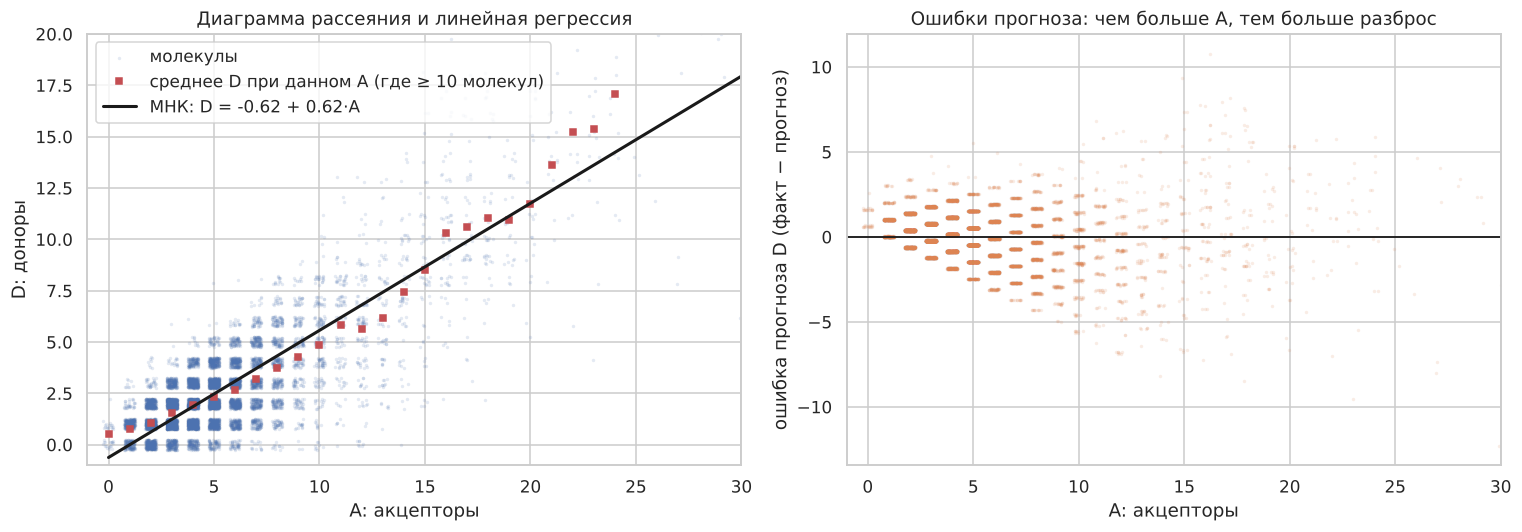

,наклон b1,сдвиг b0,R²,MAE,RMSE
A → D (все данные),0.619,-0.623,0.719,1.154,1.669
D → A (все данные),1.162,2.247,0.719,1.647,2.286
A → D (без верхнего 1%),0.521,-0.160,0.592,1.048,1.408
D → A (без верхнего 1%),1.137,2.281,0.592,1.583,2.080


In [19]:
def regression_report(x, y, k=5):
    fit = stats.linregress(x, y)                       # прямая МНК по всем данным
    order = RNG.permutation(len(x))
    pred = np.empty(len(x))
    for fold in np.array_split(order, k):              # прогноз для каждой части по остальным
        train = np.setdiff1d(order, fold)
        slope, intercept = np.polyfit(x[train], y[train], 1)
        pred[fold] = intercept + slope * x[fold]
    err = y - pred
    q1, q3 = np.percentile(y, [25, 75])
    return {
        "наклон b1": fit.slope, "сдвиг b0": fit.intercept,
        "R²": 1 - (err ** 2).sum() / ((y - y.mean()) ** 2).sum(),
        "MAE": np.abs(err).mean(), "RMSE": np.sqrt((err ** 2).mean()),
        "σ исходной": y.std(ddof=0), "IQR исходной": q3 - q1,
        "RMSE / σ": np.sqrt((err ** 2).mean()) / y.std(ddof=0),
        "MAE / IQR": np.abs(err).mean() / (q3 - q1),
        "в пределах ±1": (np.abs(np.round(pred) - y) <= 1).mean(),
    }, pred

rep_ad, pred_d = regression_report(a, d)            # A → D
rep_da, pred_a = regression_report(d, a)            # D → A
rep_ad_core, _ = regression_report(a[core], d[core])
rep_da_core, _ = regression_report(d[core], a[core])

# --- диаграмма рассеяния с прямой и график остатков
rng_j = np.random.default_rng(1)
jx, jy = rng_j.uniform(-0.25, 0.25, (2, N))
view = (a <= 30) & (d <= 20)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.scatter(a[view] + jx[view], d[view] + jy[view], s=5, alpha=0.15, color="C0", linewidths=0, label="молекулы")
mean_by_a = pd.Series(d).groupby(a).mean()
mean_by_a = mean_by_a[(mean_by_a.index <= 30) & (pd.Series(a).value_counts().reindex(mean_by_a.index) >= 10)]
ax.plot(mean_by_a.index, mean_by_a.values, "s", color="C3", ms=4, label="среднее D при данном A (где ≥ 10 молекул)")
xs = np.array([0, 30])
ax.plot(xs, rep_ad["сдвиг b0"] + rep_ad["наклон b1"] * xs, "k-", lw=2,
        label=f"МНК: D = {rep_ad['сдвиг b0']:.2f} + {rep_ad['наклон b1']:.2f}·A")
ax.set_xlim(-1, 30); ax.set_ylim(-1, 20); ax.set_xlabel("A: акцепторы"); ax.set_ylabel("D: доноры")
ax.set_title("Диаграмма рассеяния и линейная регрессия"); ax.legend(loc="upper left")
ax = axes[1]
resid = d - pred_d
ax.scatter(a[view] + jx[view], resid[view], s=5, alpha=0.15, color="C1", linewidths=0)
ax.axhline(0, color="k", lw=1.2)
ax.set_xlim(-1, 30); ax.set_xlabel("A: акцепторы"); ax.set_ylabel("ошибка прогноза D (факт − прогноз)")
ax.set_title("Ошибки прогноза: чем больше A, тем больше разброс")
plt.tight_layout()

reg_table = pd.DataFrame({
    "A → D (все данные)": rep_ad, "D → A (все данные)": rep_da,
    "A → D (без верхнего 1%)": rep_ad_core, "D → A (без верхнего 1%)": rep_da_core,
}).T[["наклон b1", "сдвиг b0", "R²", "MAE", "RMSE"]].round(3)
reg_table

#### 2.3. Взаимозаменяемость: сколько информации теряется

Если подставлять предсказанное значение вместо настоящего, то ошибка должна быть мала **по сравнению с естественным разбросом самой величины**. Сравниваем её с двумя мерами разброса: стандартным отклонением $\sigma$ (для RMSE) и межквартильным размахом IQR, то есть шириной «середины» данных (для MAE). Чем ближе отношения к 0, тем меньше потеря; отношение около 1 значит, что подстановка ничуть не лучше, чем просто взять случайное типичное значение.

Доля потерянной информации по дисперсии — это $1 - R^2$.

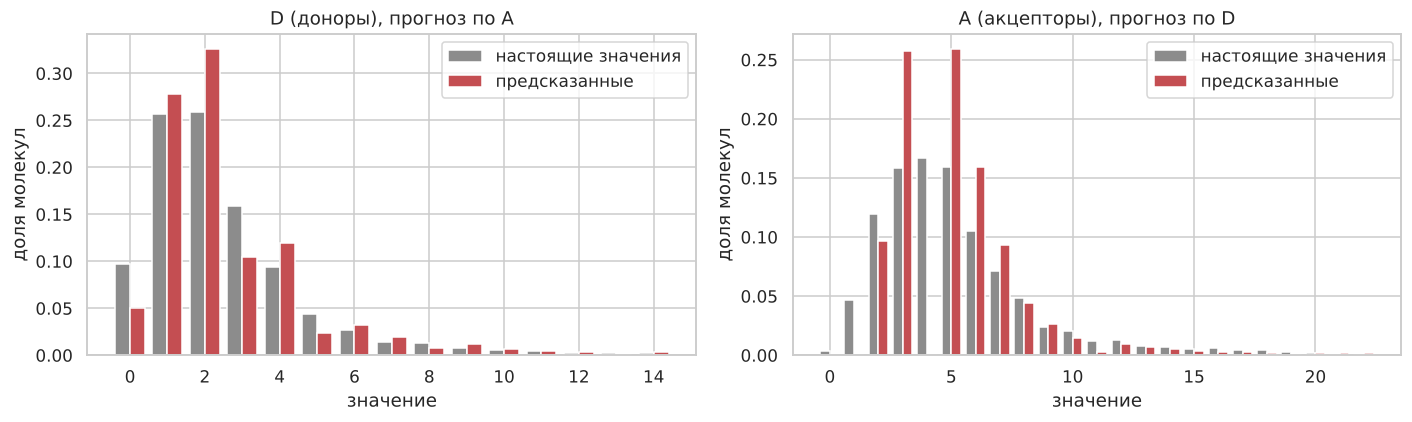

,σ исходной,IQR исходной,RMSE,RMSE / σ,MAE,MAE / IQR,потеряно дисперсии (1 − R²),прогноз в пределах ±1
A → D (все данные),3.15,2.0,1.67,0.53,1.15,0.58,0.28,0.75
D → A (все данные),4.31,3.0,2.29,0.53,1.65,0.55,0.28,0.55
A → D (без верхнего 1%),2.20,2.0,1.41,0.64,1.05,0.52,0.41,0.76
D → A (без верхнего 1%),3.26,3.0,2.08,0.64,1.58,0.53,0.41,0.56


In [20]:
swap_rows = {}
for label, rep in (("A → D (все данные)", rep_ad), ("D → A (все данные)", rep_da),
                   ("A → D (без верхнего 1%)", rep_ad_core), ("D → A (без верхнего 1%)", rep_da_core)):
    swap_rows[label] = {
        "σ исходной": rep["σ исходной"], "IQR исходной": rep["IQR исходной"],
        "RMSE": rep["RMSE"], "RMSE / σ": rep["RMSE / σ"],
        "MAE": rep["MAE"], "MAE / IQR": rep["MAE / IQR"],
        "потеряно дисперсии (1 − R²)": 1 - rep["R²"],
        "прогноз в пределах ±1": rep["в пределах ±1"],
    }
swap_table = pd.DataFrame(swap_rows).T.round(2)

# исходное распределение и распределение «заменителя» (прогноз, округлённый до целого)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, y, pred, name, xmax in ((axes[0], d, pred_d, "D (доноры), прогноз по A", 14),
                                (axes[1], a, pred_a, "A (акцепторы), прогноз по D", 22)):
    pr = np.clip(np.round(pred), 0, None).astype(int)
    ks = np.arange(xmax + 1)
    ax.bar(ks - 0.2, np.bincount(y, minlength=xmax + 1)[:xmax + 1] / N, width=0.4, color="C7", label="настоящие значения")
    ax.bar(ks + 0.2, np.bincount(pr, minlength=xmax + 1)[:xmax + 1] / N, width=0.4, color="C3", label="предсказанные")
    ax.set_xlabel("значение"); ax.set_ylabel("доля молекул"); ax.set_title(name); ax.legend()
plt.tight_layout()
swap_table

**Вывод по гипотезе 2:**

**$H_0$ отвергается: связь между A и D есть, но заменять одну величину другой нельзя без заметной потери информации.**

1. **Корреляция.** Спирмен = 0,65 (95% доверительный интервал 0,63–0,66, p < 10⁻³⁰⁰). Пирсон = 0,85 завышен редкими крупными молекулами: без верхнего 1% он равен 0,77. Средние D при каждом A лежат близко к прямой, то есть связь близка к линейной, но разброс растёт вместе с A (график ошибок), поэтому главным выбран Спирмен.
2. **Регрессия.** $D \approx -0{,}62 + 0{,}62\,A$: каждый лишний акцептор в среднем даёт около 0,6 донора. По кросс-валидации $R^2$ = 0,72 в обе стороны (в простой регрессии он равен $r^2$), MAE = 1,15 (A → D) и 1,65 (D → A), RMSE = 1,67 и 2,29. Без верхнего 1% $R^2$ снижается до 0,59: часть качества даёт небольшая группа крупных молекул.
3. **Взаимозаменяемость.** Ошибка прогноза составляет 0,53 стандартного отклонения самой величины (RMSE / σ) и 55–58% межквартильного размаха, а без верхнего 1% — 0,64 σ. Потеряно 28% разброса (41% без крупных молекул). Прогноз D по A попадает в ±1 от настоящего значения у 75% молекул, прогноз A по D — только у 55%. Предсказанные значения «сжаты» к середине: нулевых D предсказано 5% против настоящих 9,7%, а прогноз A по D вообще не даёт значений 0, 1 и 4 (настоящих A ≤ 1 около 5%).
4. **Итог.** Заменять A на D (и наоборот) допустимо только для грубой оценки; в сторону A → D ошибка меньше, чем D → A, потому что у A разброс больше. Для задач, где важны редкие и крайние значения, замена не годится.

## Шаг 8. Итог

1. **Данные:** 10 046 молекул, пропусков нет. Типичные значения: A около 5, D около 2, у редких тяжёлых молекул намного больше.
2. **Случайность:** по трём теоремам (закон больших чисел, центральная предельная теорема, Гливенко — Кантелли) A и D ведут себя как случайные величины: выборочные средние сходятся к среднему по базе, распределение выборочных средних приближается к нормальному (хорошо заметно уже при $n \ge 100$), а эмпирическая функция распределения приближается к функции всей базы как $1/\sqrt{n}$.
3. **Связь:** A и D связаны положительно и надёжно (Спирмен 0,65; Пирсон 0,85, но он завышен из-за редких гигантов).
4. **Оценки:** среднее и корреляция по выборкам сходятся к значениям по всей базе, данных хватает с запасом.
5. **Форма данных:** сильно скошены вправо; логарифм `ln(1+x)` делает их почти симметричными. Выбросы — настоящие тяжёлые молекулы, оставляем.
6. **Выборки:** оба способа дают правильное среднее; без возвращения точнее, если берём большую часть базы.
7. **Распределение:** Пуассон не подходит (разброс в 3–4 раза больше среднего), отрицательное биномиальное лучше, но хвост описывает неидеально.
8. **Гипотезы:** A и D зависят от `state`, но слабо (сильнее всего отличается группа `liquid`); A нельзя заменить на D без потери информации (потеряно 28% разброса, $R^2$ = 0,72).

**Для следующего этапа (генератор):** так как A и D связаны, генерировать их надо не независимо, а вместе или D при заданном A.